# Landslide Susceptibility Map Generation — Sri Lanka

## 1. Setup

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
import geopandas as gpd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

ROOT = Path(os.environ.get("LANDSLIDE_ROOT", Path.cwd().parent))
DATA = ROOT / "data" / "processed"
RAW  = ROOT / "data" / "raw" / "Sri_Lanka_dataset"
OUT  = DATA / "predictions" / "sri_lanka_susceptibility"
OUT.mkdir(parents=True, exist_ok=True)

NODATA = -9999.0

## 2. Train the model on the factors that exist as rasters

In [2]:
CONTINUOUS  = ["elev", "slope", "aspect", "twi", "spi", "clay", "sand", "soc", "bdod"]
CATEGORICAL = ["landcover"]
FEATURES = CONTINUOUS + CATEGORICAL

X_train = pd.read_csv(DATA / "sri_lanka_X_train_raw.csv")[FEATURES]
X_test  = pd.read_csv(DATA / "sri_lanka_X_test_raw.csv")[FEATURES]
y_train = pd.read_csv(DATA / "sri_lanka_y_train.csv").squeeze("columns")
y_test  = pd.read_csv(DATA / "sri_lanka_y_test.csv").squeeze("columns")

model = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), CONTINUOUS),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])),
    ("rf", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_split=10,
                                  min_samples_leaf=4, max_features="sqrt", random_state=42, n_jobs=-1)),
])
model.fit(X_train, y_train)

from sklearn.metrics import roc_auc_score
print("Test ROC-AUC:", round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3))

Test ROC-AUC: 0.688


## 3. Put all covariate rasters on the same grid

In [3]:
# The slope raster (30 m, UTM 44N) is the reference grid
with rasterio.open(DATA / "slope.tif") as ref:
    profile, shape = ref.profile, ref.shape

def to_ref_grid(src_path, resampling, scale=1.0):
    # reproject a raster onto the reference grid
    out = np.full(shape, np.nan, dtype="float32")
    with rasterio.open(src_path) as src:
        reproject(rasterio.band(src, 1), out, src_transform=src.transform, src_crs=src.crs,
                  src_nodata=src.nodata, dst_transform=profile["transform"], dst_crs=profile["crs"],
                  dst_nodata=np.nan, resampling=resampling)
    return out / scale

def read(path):
    with rasterio.open(path) as src:
        a = src.read(1).astype("float32")
        return np.where(a == src.nodata, np.nan, a)

layers = {name: read(DATA / f"{f}.tif") for name, f in
          [("elev", "dem_utm"), ("slope", "slope"), ("aspect", "aspect"), ("twi", "twi"), ("spi", "spi")]}

for name, div in [("clay", 10), ("sand", 10), ("soc", 10), ("bdod", 100)]:
    layers[name] = to_ref_grid(RAW / "soilgrids" / f"soilgrids_{name}.tif", Resampling.bilinear, div)

lc = to_ref_grid(RAW / "worldcover" / "sri_lanka_worldcover_mosaic.tif", Resampling.nearest)
layers["landcover"] = np.where(lc == 0, np.nan, lc)      # 0 = no data

## 4. Predict probability for every valid cell

In [4]:
# A cell is valid only if every factor has a value
stack = np.stack([layers[f].ravel() for f in FEATURES], axis=1)
valid = np.isfinite(stack).all(axis=1)
print(f"Valid cells: {valid.sum():,} of {valid.size:,}")

# Predict in batches to limit memory use
proba = np.full(valid.size, np.nan, dtype="float32")
idx = np.flatnonzero(valid)
for i in range(0, len(idx), 500_000):
    rows = idx[i:i + 500_000]
    proba[rows] = model.predict_proba(pd.DataFrame(stack[rows], columns=FEATURES))[:, 1]

Valid cells: 11,292,312 of 25,064,832


C:\Users\PCC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\PCC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\PCC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed

## 5. Convert the probabilities back to a raster

In [5]:
prob_map = proba.reshape(shape)          # same cell order as the input grid

profile.update(dtype="float32", count=1, nodata=NODATA, compress="lzw")
with rasterio.open(OUT / "susceptibility_probability.tif", "w", **profile) as dst:
    dst.write(np.nan_to_num(prob_map, nan=NODATA).astype("float32"), 1)

## 6. Clip to the study area

In [6]:
# Study-area polygons saved by 01_study_area (UTM 44N, one row per district)
areas = gpd.read_file(DATA / "aoi.gpkg", layer="districts")
NAMES = ["Kandy", "Nuwara Eliya", "Kegalle", "Badulla"]     # target districts
areas = areas[areas["adm2_name"].isin(NAMES)]
assert len(areas) == len(NAMES), "district name not found in aoi.gpkg"

with rasterio.open(OUT / "susceptibility_probability.tif") as src:
    areas = areas.to_crs(src.crs)
    clipped, transform = mask(src, areas.geometry, crop=True, nodata=NODATA)
    profile = src.profile

profile.update(height=clipped.shape[1], width=clipped.shape[2], transform=transform)
with rasterio.open(OUT / "susceptibility_probability_clipped.tif", "w", **profile) as dst:
    dst.write(clipped)

prob = np.where(clipped[0] == NODATA, np.nan, clipped[0])
print("Clipped raster:", prob.shape, "| scored cells:", np.isfinite(prob).sum())

Clipped raster: (3887, 4048) | scored cells: 8695487


## 7. Visualise the probability surface

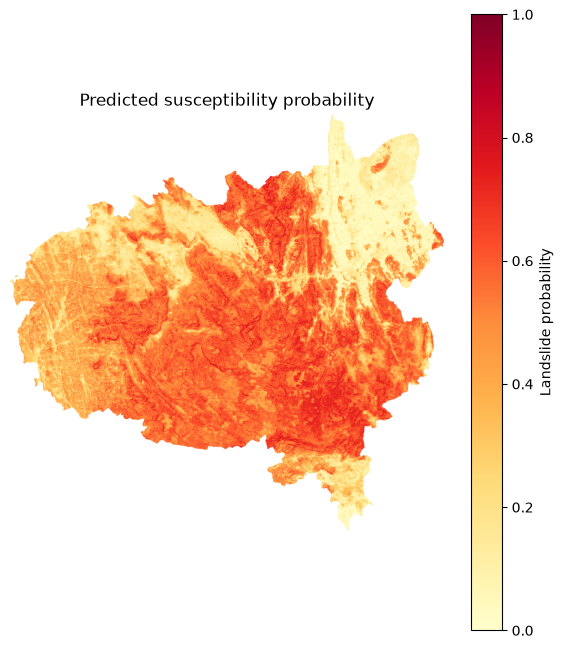

In [7]:
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(prob, cmap="YlOrRd", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Landslide probability")
ax.set_title("Predicted susceptibility probability")
ax.axis("off")
plt.savefig(OUT / "probability_surface.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Classify into susceptibility classes

In [8]:
# Thresholds = 20th, 40th, 60th and 80th percentiles of the clipped study-area probabilities
values = prob[np.isfinite(prob)]
breaks = np.quantile(values, [0.2, 0.4, 0.6, 0.8])
print("Class breaks:", np.round(breaks, 3))

labels = ["Very Low", "Low", "Moderate", "High", "Very High"]
classes = np.zeros(prob.shape, dtype="uint8")                 # 0 = no data
ok = np.isfinite(prob)
classes[ok] = np.digitize(prob[ok], breaks) + 1               # 1 ... 5

pixel_km2 = abs(transform.a * transform.e) / 1e6
table = pd.DataFrame({"class": labels,
                      "area_km2": [round((classes == k).sum() * pixel_km2, 1) for k in range(1, 6)]})
table["area_%"] = (100 * table.area_km2 / table.area_km2.sum()).round(1)
table

Class breaks: [0.205 0.415 0.533 0.615]


,class,area_km2,area_%
0,Very Low,1638.8,20.0
1,Low,1638.8,20.0
2,Moderate,1638.8,20.0
3,High,1638.8,20.0
4,Very High,1638.8,20.0


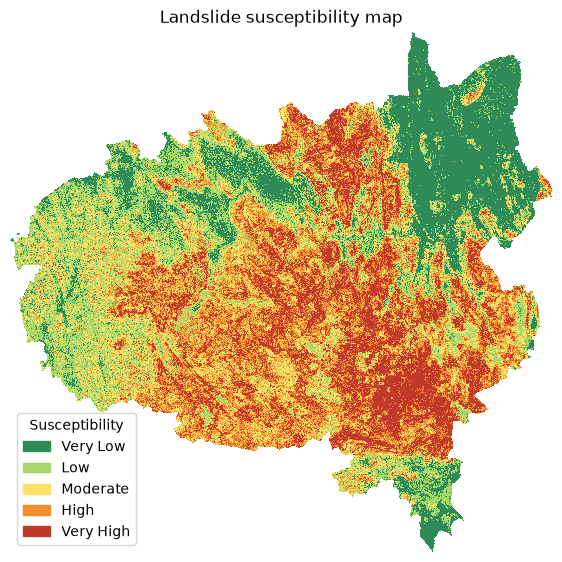

In [9]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colors = ["#2E8B57", "#A6D96A", "#FFE066", "#F28E2B", "#C0392B"]
fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(np.ma.masked_equal(classes, 0), cmap=ListedColormap(colors), vmin=0.5, vmax=5.5, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)], loc="lower left", title="Susceptibility")
ax.set_title("Landslide susceptibility map")
ax.axis("off")
plt.savefig(OUT / "susceptibility_map.png", dpi=300, bbox_inches="tight")
plt.show()

profile.update(dtype="uint8", nodata=0)
with rasterio.open(OUT / "susceptibility_classes.tif", "w", **profile) as dst:
    dst.write(classes, 1)
table.to_csv(OUT / "class_areas.csv", index=False)

## Optional check A. Do the classes match held-out landslides?

In [10]:
from sklearn.model_selection import train_test_split

# Rebuild the test split from the 08c notebook to recover test-point coordinates
df = pd.read_csv(DATA / "training_table_sri_lanka_kerala_factors.csv")
cols = list(pd.read_csv(DATA / "sri_lanka_X_train_raw.csv").columns)
df = df[["label"] + cols + ["x", "y"]].dropna(subset=cols).reset_index(drop=True)
_, test = train_test_split(df, test_size=0.2, stratify=df.label, random_state=42)

with rasterio.open(OUT / "susceptibility_probability_clipped.tif") as src:
    test["prob"] = [v[0] for v in src.sample(zip(test.x, test.y))]
test = test[test.prob != NODATA]
test["class"] = np.digitize(test.prob, breaks) + 1

slides = test[test.label == 1]
check = table.copy()
check["landslide_%"] = [round(100 * (slides["class"] == k).mean(), 1) for k in range(1, 6)]
check["frequency_ratio"] = (check["landslide_%"] / check["area_%"]).round(2)   # >1 = more landslides than expected
check

,class,area_km2,area_%,landslide_%,frequency_ratio
0,Very Low,1638.8,20.0,2.7,0.14
1,Low,1638.8,20.0,8.2,0.41
2,Moderate,1638.8,20.0,16.4,0.82
3,High,1638.8,20.0,24.7,1.23
4,Very High,1638.8,20.0,47.9,2.40


## Optional check B. Are any cells outside the range seen in training?

In [11]:
# Useful before applying the model to a new location
outside = pd.Series({f: round(100 * ((layers[f] < X_train[f].min()) | (layers[f] > X_train[f].max())).sum()
                              / valid.sum(), 2) for f in CONTINUOUS}, name="% of valid cells outside training range")
outside

elev      11.34
slope      0.09
aspect     0.09
twi        0.11
spi        0.16
clay       0.39
sand       0.02
soc        0.03
bdod       1.87
Name: % of valid cells outside training range, dtype: float64

## 9. Susceptibility map for each district

In [12]:
districts = gpd.read_file(DATA / "aoi.gpkg", layer="districts")
districts = districts[districts["adm2_name"].isin(NAMES)]

# Inventory points (UTM 44N) with the same train/test split as the modelling notebook
from sklearn.model_selection import train_test_split
cols = list(pd.read_csv(DATA / "sri_lanka_X_train_raw.csv").columns)
df = pd.read_csv(DATA / "training_table_sri_lanka_kerala_factors.csv")
df = df[["label"] + cols + ["x", "y"]].dropna(subset=cols).reset_index(drop=True)
_, test_idx = train_test_split(df.index, test_size=0.2, stratify=df.label, random_state=42)
df["set"] = np.where(df.index.isin(test_idx), "test", "train")

# Attach each point to its district, then read the predicted probability and class at the point
pts = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y), crs="EPSG:32644")
pts = gpd.sjoin(pts, districts[["adm2_name", "geometry"]], predicate="within")
with rasterio.open(OUT / "susceptibility_probability.tif") as src:
    pts["prob"] = [v[0] for v in src.sample(zip(pts.x, pts.y))]
pts = pts[pts.prob != NODATA].copy()
pts["class"] = np.digitize(pts.prob, breaks) + 1
print(pts.groupby(["adm2_name", "set"]).size().unstack(fill_value=0))

set           test  train
adm2_name                
Badulla         54    238
Kandy          125    451
Kegalle         33    113
Nuwara Eliya    81    367


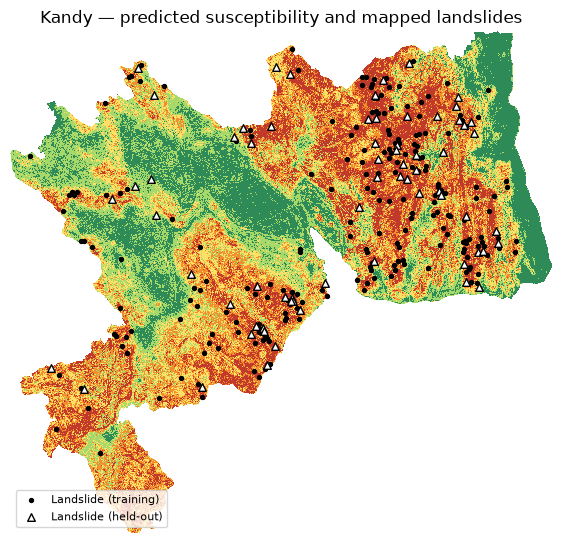

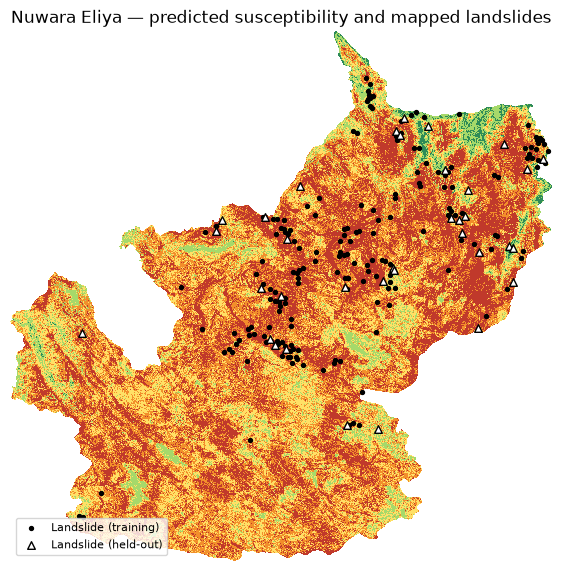

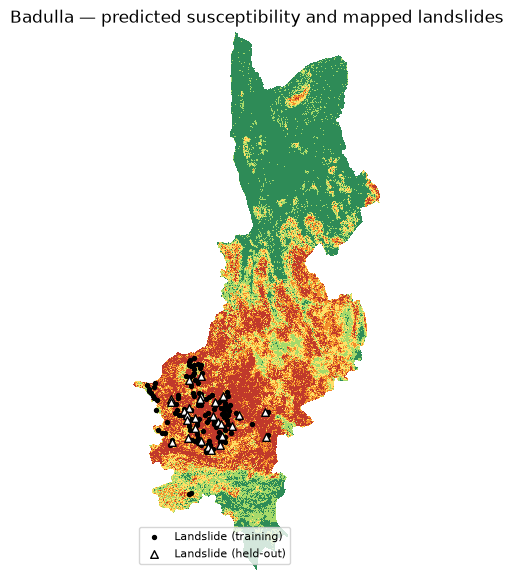

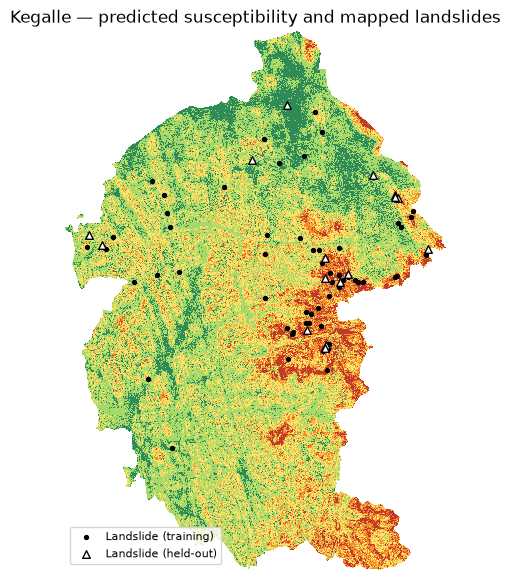

In [13]:
with rasterio.open(OUT / "susceptibility_classes.tif") as src:
    for _, d in districts.iterrows():
        arr, tr = mask(src, [d.geometry], crop=True, nodata=0)
        extent = (tr.c, tr.c + tr.a * arr.shape[2], tr.f + tr.e * arr.shape[1], tr.f)

        fig, ax = plt.subplots(figsize=(7, 7))
        ax.imshow(np.ma.masked_equal(arr[0], 0), cmap=ListedColormap(colors), vmin=0.5, vmax=5.5,
                  extent=extent, interpolation="nearest")
        p = pts[(pts.adm2_name == d.adm2_name) & (pts.label == 1)]          # actual landslides
        ax.scatter(p[p.set == "train"].x, p[p.set == "train"].y, s=8, c="black", label="Landslide (training)")
        ax.scatter(p[p.set == "test"].x, p[p.set == "test"].y, s=30, c="white", edgecolors="black",
                   marker="^", label="Landslide (held-out)")
        ax.set_title(f"{d.adm2_name} — predicted susceptibility and mapped landslides")
        ax.legend(loc="lower left", fontsize=8); ax.axis("off")
        plt.savefig(OUT / f"susceptibility_map_{d.adm2_name.replace(' ', '_')}.png", dpi=300, bbox_inches="tight")
        plt.show()

## 10. Predicted vs actual by district

In [14]:
from sklearn.metrics import roc_auc_score

def summarise(g):
    slides = g[g.label == 1]
    return pd.Series({
        "landslides": len(slides),
        "mean prob (landslide)": slides.prob.mean(),
        "mean prob (non-landslide)": g[g.label == 0].prob.mean(),
        "% landslides in High+Very High": 100 * (slides["class"] >= 4).mean(),
        "ROC-AUC": roc_auc_score(g.label, g.prob) if g.label.nunique() == 2 else np.nan,
    })

# Share of each district's area predicted High or Very High
area_hi = {}
with rasterio.open(OUT / "susceptibility_classes.tif") as src:
    for _, d in districts.iterrows():
        a = mask(src, [d.geometry], crop=True, nodata=0)[0][0]
        area_hi[d.adm2_name] = 100 * (a[a > 0] >= 4).mean()

result = pts[pts.set == "test"].groupby("adm2_name").apply(summarise)        # held-out points only
result["% area High+Very High"] = pd.Series(area_hi)
result["frequency ratio"] = result["% landslides in High+Very High"] / result["% area High+Very High"]
result.round(2)

,landslides,mean prob (landslide),mean prob (non-landslide),% landslides in High+Very High,ROC-AUC,% area High+Very High,frequency ratio
adm2_name,,,,,,,
Badulla,28.0,0.64,0.41,89.29,0.83,37.60,2.37
Kandy,67.0,0.59,0.46,74.63,0.75,41.09,1.82
Kegalle,16.0,0.47,0.38,43.75,0.68,15.03,2.91
Nuwara Eliya,35.0,0.56,0.56,68.57,0.52,66.47,1.03


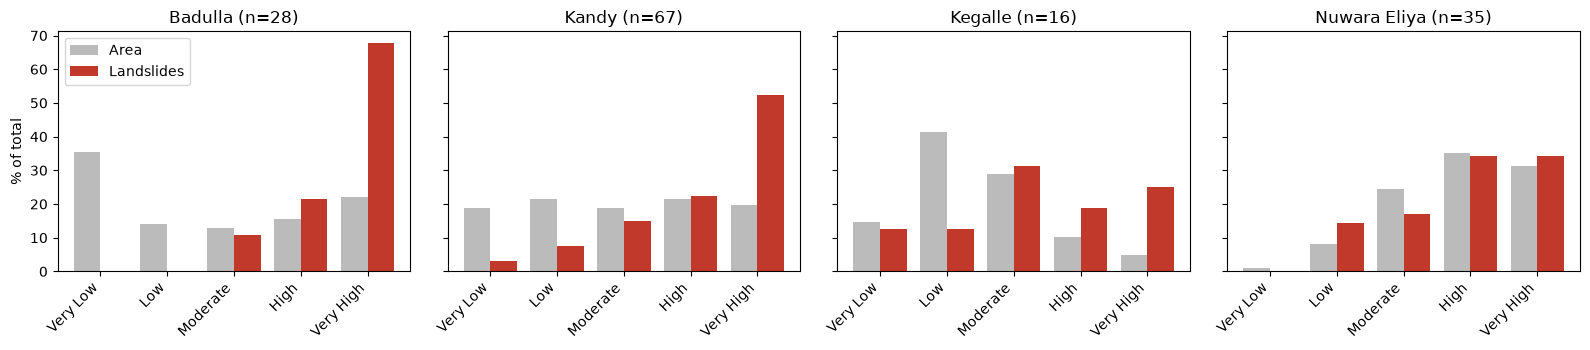

In [15]:
# Share of landslides vs share of area in each class, per district (held-out points)
names = list(result.index)
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3.6), sharey=True, squeeze=False)
with rasterio.open(OUT / "susceptibility_classes.tif") as src:
    for ax, name in zip(axes[0], names):
        a = mask(src, [districts[districts.adm2_name == name].geometry.iloc[0]], crop=True, nodata=0)[0][0]
        area = [100 * (a == k).sum() / (a > 0).sum() for k in range(1, 6)]
        p = pts[(pts.adm2_name == name) & (pts.set == "test") & (pts.label == 1)]
        slides = [100 * (p["class"] == k).mean() for k in range(1, 6)]
        x = np.arange(5)
        ax.bar(x - 0.2, area, 0.4, label="Area", color="#BBBBBB")
        ax.bar(x + 0.2, slides, 0.4, label="Landslides", color="#C0392B")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_title(f"{name} (n={len(p)})")
axes[0][0].set_ylabel("% of total"); axes[0][0].legend()
plt.tight_layout(); plt.savefig(OUT / "predicted_vs_actual_by_district.png", dpi=300); plt.show()